# Post5G - TDD Patterns

## Prerequisites

Before starting, make sure you:

- Have completed the [Simple Scenario](./10_simple.ipynb) and [Adding component](./11_add_components.ipynb) tutorials.
- Have a basic understanding of Python.
- Have a good understanding of the 5G architecture.
- Have a good undesrtanding of Time Division Duplex (TDD)

## Experiment for this scenario

In this scenario, we will modify the TDD configuration of the gNB named `gnb`
and measure the impact of the change on the performances.

The figure below show the 5G network we are considering.

![TDD toplogy](./figures/tdd.png)

We will now provision our infrastructure and deploy the 5G network.


In [1]:
from metamodel.models.metamodel import MetaModel

metamodel=MetaModel.from_yaml(
"""
ran:
  components:
    gnb:
      type: gnb

ues:
  sim_ue1:
    config:
      supi: '001010000000100'
      gnbs:
      - gnb
  sim_ue2:
    config:
      supi: '001010000000101'
      gnbs:
      - gnb
""")

In [2]:
from orchestrator.models.deployment import DeploymentModel

deployment_model = DeploymentModel.from_yaml(
"""
core:
  implementation: open5gs

ran:
  components:
    gnb:
      type: gnb
      implementation: oai

ues:
  sim_ue1:
    implementation: oai
    type: containerized
  sim_ue2:
    implementation: oai
    type: containerized

nodes:
  node-core:
    provisioner: my-provisionner
    roles:
    - core
    - ric
  node-ran:
    provisioner: my-provisionner
    roles:
    - ran
  node-ues:
    provisioner: my-provisionner
    roles:
    - ue

provisioners:
  my-provisionner:
    type: bi
    params:
      infra: be-gent1-bi-vm1
      project: post5g-beta
      experiment: tdd_scenario_simple
      create_experiment: true
      experiment_duration: 1h
      node_duration: 1h
"""
)

In [3]:
from orchestrator.deployment import ProvisioningManagement

prov = ProvisioningManagement(metamodel=metamodel, deployment_model=deployment_model)
await prov.provision(quiet=False)

from orchestrator.deployment import K8SManagement

k8s = K8SManagement(preceding=prov)
await k8s.deploy(quiet=True)

[WARNING]: No inventory was parsed, only implicit localhost is available
[WARNING]: No inventory was parsed, only implicit localhost is available
[WARNING]: No inventory was parsed, only implicit localhost is available
[WARNING]: provided hosts list is empty, only localhost is available. Note that the implicit localhost does not match 'all'
[WARNING]: provided hosts list is empty, only localhost is available. Note that the implicit localhost does not match 'all'
[WARNING]: provided hosts list is empty, only localhost is available. Note that the implicit localhost does not match 'all'

PLAY [localhost] ***************************************************************

PLAY [localhost] ***************************************************************

PLAY [localhost] ***************************************************************

TASK [provisioning/bi/provision : Select project 'post5g-beta' for 'node-ran' provisioning] ***

TASK [provisioning/bi/provision : Select project 'post5g-beta' fo

In [4]:
from orchestrator.deployment import CoreManagement
core = CoreManagement(preceding=k8s)
await core.deploy(quiet=True)

from orchestrator.deployment import RANManagement
ran = RANManagement(preceding=core)
await ran.deploy(quiet=True)

from orchestrator.deployment import UEManagement
ues = UEManagement(preceding=ran)
await ues.deploy(quiet=True)

/workspaces/orchestrator/.venv-1/lib/python3.12/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='snssaiList', input_value=Slice(sst=1, sd=None, nam...maximumBitRate=None)])}), input_type=Slice])
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='ru', input_value=RU(type=<RUType.SIMULATED...xGainDB=35, rxGainDB=75), input_type=RU])
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='amf', input_value=IPv4Address('10.244.134.7'), input_type=IPv4Address])
  return self.__pydantic_serializer__.to_python(


Let's first determine the current TDD pattern on `gnb2`. This information is stored in the `radioConfiguration.tddConfiguration` attribute of the gNB configuration in the metamodel.


In [5]:
tdd = metamodel.ran.components["gnb"].config.radioConfiguration.tddConfiguration
print (tdd.to_yaml(exclude_defaults=False))

periodicityMilliseconds: 5.0
nrofDownlinkSlots: 7
nrofDownlinkSymbols: 6
nrofUplinkSlots: 2
nrofUplinkSymbols: 4



We can also represent this setting in a more user friendly way.

In [6]:
! pip install matplotlib

Current TDD pattern is: DDDDDDDSUU


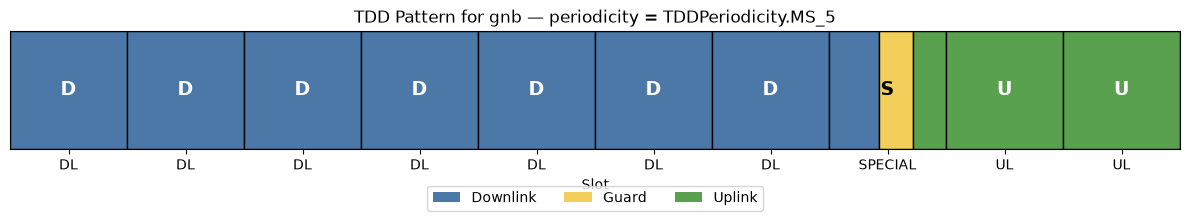

In [7]:
from tdd import generate_tdd_pattern, plot_tdd_pattern
pattern = generate_tdd_pattern(tdd)
print (f"Current TDD pattern is: {pattern}")
plot_tdd_pattern(gnb="gnb", tdd=tdd)

## Measure delay and througput

We can now measure the delay and throughput at the UE.

To remove the impact of the data network (N6 interface), we will measure these
metrics between the UE and the tunnel endpoint at the UPF. Its IP address is
`11.1.1.1` in our scenario.

In [8]:
PING_COUNT=60
IPERF_DURATION=60
ENDPOINT="11.1.1.1"

### Delay measurement

We measure the delay as the value obtained by a ping to the UPF. First we run
the ping command, then we can plot its evolution with time.

In [9]:
command = ["ping", "-I", "oaitun_ue1", "-c", PING_COUNT, "-D", ENDPOINT]
ping = (await ues.run_command(command=command, components=["sim_ue1"], quiet=False))


PLAY [node-core] ***************************************************************

TASK [helm/run_cmd : Get Pod for 'oai-sim-ue1' Helm chart] *********************
[WARNING]: Host 'node-core' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
[WARNING]: kubernetes<24.2.0 is not supported or tested. Some features may not work.
ok: [node-core]

TASK [helm/run_cmd : Run 'ping -I oaitun_ue1 -c 60 -D 11.1.1.1' on 'oai-sim-ue1' Helm chart] ***
[WARNING]: Deprecation warnings can be disabled by setting `deprecation_warnings=False` in ansible.cfg.
[DEPRECATION WARNING]: The 'return_code' return value is deprecated and will be removed in version 7.0.0. Use 'rc' instead. This feature will be removed from collection 'kubernetes.core' version 7.0.0.
changed: 

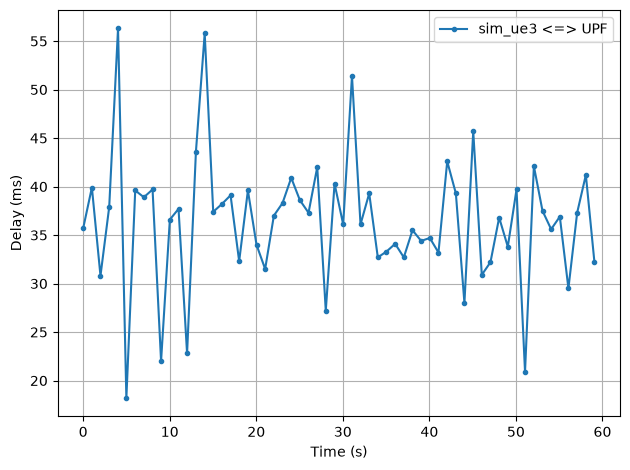

In [10]:
import re
def parse_ping(ping_output):
    pings = [
    (float(timestamp), float(delay))
    for timestamp, delay in re.findall(
        r'\[(\d+\.\d+)\].*time[=<]([\d.]+)\s*ms',
        ping_output
    )
    ]
    return pings

import matplotlib.pyplot as plt
def plot_ping(data, label, savefile=None):
    points = parse_ping(data)
    timestamps, delays = zip(*points)

    t0 = timestamps[0]
    elapsed = [t - t0 for t in timestamps]

    plt.plot(elapsed, delays, marker=".", label=label)

    plt.xlabel("Time (s)")
    plt.ylabel("Delay (ms)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    
    if savefile is not None:
        plt.savefig(savefile, dpi=300, bbox_inches="tight")
    plt.show()

plot_ping(data=ping, label="sim_ue3 <=> UPF")

### Througput measurement

We measure the troughput as the result of running TCP iPerf 3 between the UE and
the UPF.

To do it, we first need to start an `iperf3` daemon on the UPF then we can run
the `iperf31 client on the UE.

In [11]:
from orchestrator.deployment import CoreManagement
core = CoreManagement(preceding=ues)

command = ["iperf3", "-s", "-D", "--logfile", "/iperf3.log"]
result = (await core.run_command(command=command, components=["upf"], quiet=True))


In [12]:
command = ["bash", "-c", "'ip -4 addr show oaitun_ue1 | grep -oP \"(?<=inet )\\d+(\\.\\d+){3}\"'"]
sim_ue1_ip = (await ues.run_command(command=command, components=["sim_ue1"], quiet=True)).rstrip()
print (f"IP address of sim_ue1 {sim_ue1_ip}")

command = ["iperf3", "-c", ENDPOINT, "-B", sim_ue1_ip, "-t" , IPERF_DURATION, "-J", "--bidir"]
result = (await ues.run_command(command=command, components=["sim_ue1"], quiet=True))

IP address of sim_ue1 11.1.1.2


In [13]:
import json
def plot_throughput(iperf_json: str, title: str = "Bi-directional Throughput", savefile=None):
    data = json.loads(iperf_json)

    ul_time, ul_mbps = [], []
    dl_time, dl_mbps = [], []

    for interval in data["intervals"]:
        end_time = interval["sum"]["end"]

        # In --bidir mode, individual direction details sit inside interval["streams"]
        for stream in interval["streams"]:
            mbps = stream["bits_per_second"] / 1e6

            # Identify direction: stream 1 is local sender (Uplink), stream 2 is local receiver (Downlink)
            if stream.get("sender", False):
                ul_time.append(end_time)
                ul_mbps.append(mbps)
            else:
                dl_time.append(end_time)
                dl_mbps.append(mbps)

    # Plot the figure
    plt.figure(figsize=(10, 5))

    plt.plot(
        ul_time,
        ul_mbps,
        marker="o",
        color="b",
        linestyle="-",
        linewidth=2,
        label="Downlink (RX)",
    )
    plt.plot(
        dl_time,
        dl_mbps,
        marker="s",
        color="r",
        linestyle="--",
        linewidth=2,
        label="Uplink (TX)",
    )

    plt.title(title)
    plt.xlabel("Time (s)")
    plt.ylabel("Bitrate (Mbps)")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.ylim(bottom=0)
    plt.legend()

    if savefile is not None:
        plt.savefig(savefile, dpi=300, bbox_inches="tight")
        plt.show()
    plt.show()

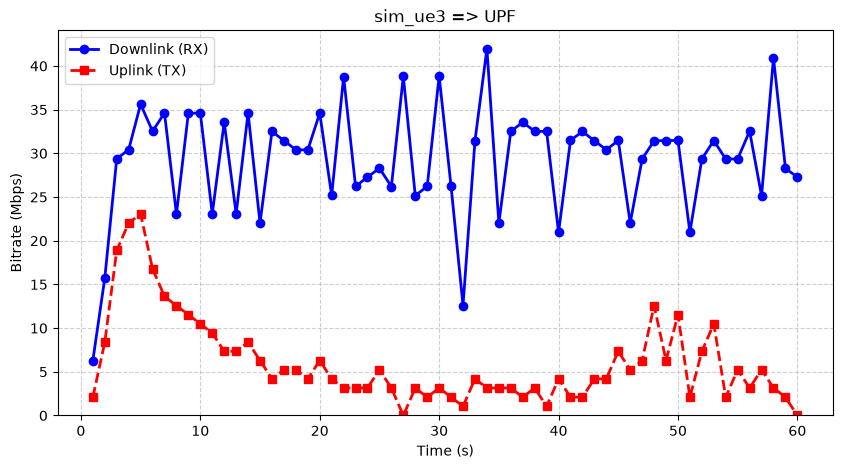

In [14]:
plot_throughput(result, " sim_ue3 => UPF ")


## Change TTD pattern

We now change the TDD pattern to have 5 downlink slots and 4 uplink slots, also
described as `DDDDDSUUUU`.

Unfortunately OAI does not support radio configuration changes on the fly. The
solution is then to remove the gNB from the RAN and create a new instance with
the new configuration with the help of a `RANManagement` manager.  It also
implies to remove the UE and relaunch it after the gNB is restarted as we use a
simulated radio channel bounding UE and gNB instances.

In [15]:
await ues.uninstall(components=["sim_ue1"])


PLAY [node-core] ***************************************************************

TASK [helm/uninstall : Uninstall 'oai-sim-ue1' Helm chart] *********************
[WARNING]: Host 'node-core' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
[WARNING]: Deprecation warnings can be disabled by setting `deprecation_warnings=False` in ansible.cfg.
[DEPRECATION WARNING]: The 'status.values' return value is deprecated and will be removed in version 8.0.0. Use 'status.release_values' instead. This feature will be removed from collection 'kubernetes.core' version 8.0.0.
changed: [node-core]

TASK [helm/uninstall : Wait for 'oai-sim-ue1' pod to be deleted] ***************
ok: [node-core]

TASK [helm/uninstall : Clean up Helm build directory for 'oai-sim-u

In [16]:
ran = RANManagement(preceding=ues)
await ran.uninstall(components=["gnb"])


PLAY [node-core] ***************************************************************

TASK [helm/uninstall : Uninstall 'oai-gnb' Helm chart] *************************
[WARNING]: Host 'node-core' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
[WARNING]: Deprecation warnings can be disabled by setting `deprecation_warnings=False` in ansible.cfg.
[DEPRECATION WARNING]: The 'status.values' return value is deprecated and will be removed in version 8.0.0. Use 'status.release_values' instead. This feature will be removed from collection 'kubernetes.core' version 8.0.0.
changed: [node-core]

TASK [helm/uninstall : Wait for 'oai-gnb' pod to be deleted] *******************
ok: [node-core]

TASK [helm/uninstall : Clean up Helm build directory for 'oai-gnb' 

We add the gNB in the same way as before, except that we augmented its metamodel
with the TDD Configuration of our will.

In [17]:

import yaml
merged_model = yaml.safe_load(
"""
type: gnb
implementation: oai
config:
  radioConfiguration:
    tddConfiguration:
      periodicityMilliseconds: 5.0
      nrofDownlinkSlots: 5
      nrofDownlinkSymbols: 6
      nrofUplinkSlots: 4
      nrofUplinkSymbols: 4
""")

ran.add_component(name="gnb", merged=merged_model)
await ran.deploy()


/workspaces/orchestrator/.venv-1/lib/python3.12/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='snssaiList', input_value=Slice(sst=1, sd=None, nam...maximumBitRate=None)])}), input_type=Slice])
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='ru', input_value=RU(type=<RUType.SIMULATED...xGainDB=35, rxGainDB=75), input_type=RU])
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='amf', input_value=IPv4Address('10.244.134.7'), input_type=IPv4Address])
  return self.__pydantic_serializer__.to_python(



PLAY [node-core] ***************************************************************

TASK [helm/prepare : Create Helm build directory for 'oai-gnb' chart] **********
[WARNING]: Host 'node-core' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
ok: [node-core]

TASK [helm/prepare : Copy custom Helm chart directory for 'oai-gnb' if provided] ***
skipping: [node-core]

TASK [helm/prepare : Copy local built-in 'oai-gnb' Helm chart directory for 'oai-gnb'] ***
ok: [node-core]

TASK [helm/prepare : Render built-in Helm Chart.yaml templated file for 'oai-gnb'] ***
ok: [node-core]

TASK [helm/prepare : Render custom templated Helm files for 'oai-gnb' if provided] ***
skipping: [node-core]

TASK [helm/prepare : Render built-in templated Helm files for 'oai-

Let's check that the Manager uses the proper TDD configuration. Note that we
use the metamodel of the manager directly.

periodicityMilliseconds: 5.0
nrofDownlinkSlots: 5
nrofDownlinkSymbols: 6
nrofUplinkSlots: 4
nrofUplinkSymbols: 4

Current TDD pattern is: DDDDDSUUUU


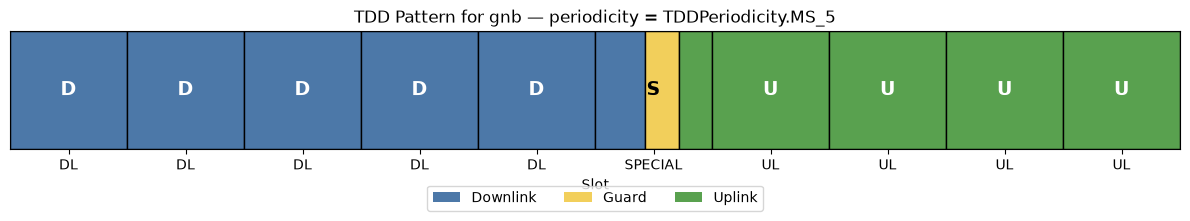

In [18]:
tdd = ran.metamodel.ran.components["gnb"].config.radioConfiguration.tddConfiguration
print (tdd.to_yaml(exclude_defaults=False))
pattern = generate_tdd_pattern(tdd)
print (f"Current TDD pattern is: {pattern}")
plot_tdd_pattern(gnb="gnb", tdd=tdd)

We can now re-deploy the UE.

In [19]:
ues = UEManagement(preceding=ran)
await ues.deploy(components=["sim_ue1"])


PLAY [node-core] ***************************************************************

TASK [helm/prepare : Create Helm build directory for 'oai-sim-ue1' chart] ******
[WARNING]: Host 'node-core' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
ok: [node-core]

TASK [helm/prepare : Copy custom Helm chart directory for 'oai-sim-ue1' if provided] ***
skipping: [node-core]

TASK [helm/prepare : Copy local built-in 'oai-containerized' Helm chart directory for 'oai-sim-ue1'] ***
ok: [node-core]

TASK [helm/prepare : Render built-in Helm Chart.yaml templated file for 'oai-sim-ue1'] ***
ok: [node-core]

TASK [helm/prepare : Render custom templated Helm files for 'oai-sim-ue1' if provided] ***
skipping: [node-core]

TASK [helm/prepare : Render built-in temp

The UE is now attached to the gNB and we can measure and represent the delay and throughput as we did earlier in this tutorial in order to compare the achieved performance over the radio link.

### Delay measurement

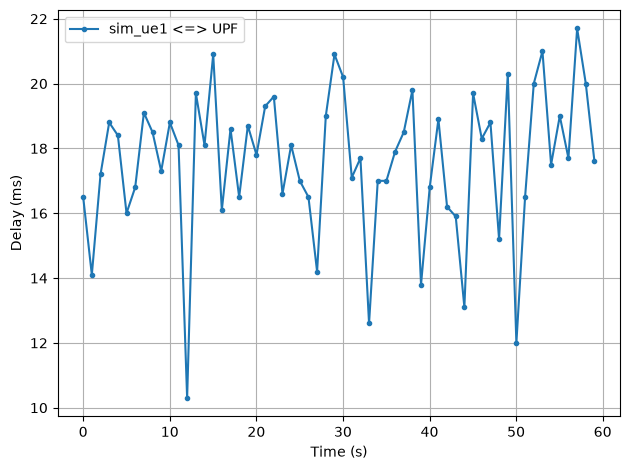

In [20]:
command = ["ping", "-I", "oaitun_ue1", "-c", PING_COUNT, "-D", ENDPOINT]
ping = (await ues.run_command(command=command, components=["sim_ue1"], quiet=True))
plot_ping(data=ping, label="sim_ue1 <=> UPF")

### Throughput measurement


In [21]:
command = ["bash", "-c", "'ip -4 addr show oaitun_ue1 | grep -oP \"(?<=inet )\\d+(\\.\\d+){3}\"'"]
sim_ue1_ip = (await ues.run_command(command=command, components=["sim_ue1"], quiet=True)).rstrip()
print (f"IP address of sim_ue1 {sim_ue1_ip}")

command = ["iperf3", "-c", ENDPOINT, "-B", sim_ue1_ip, "-t" , IPERF_DURATION, "-J", "--bidir"]
result = (await ues.run_command(command=command, components=["sim_ue1"], quiet=True))


IP address of sim_ue1 11.1.1.4


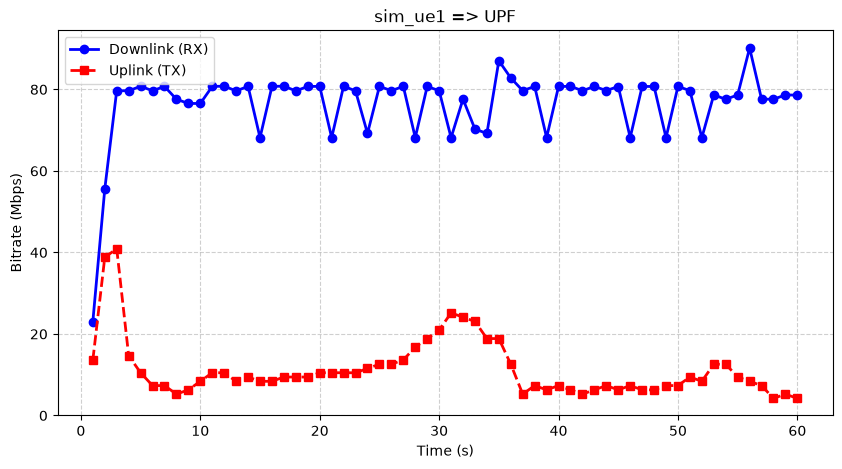

In [22]:
plot_throughput(result, " sim_ue1 => UPF ")

As usual let's archive our metamodel and deployment model.

In [23]:
from pathlib import Path
DIR="state/tdd"
Path(DIR).mkdir(parents=True, exist_ok=True)

ues.metamodel.to_yaml_file(f"{DIR}/metamodel.ues.yaml")
ues.deployment_model.to_yaml_file(f"{DIR}/deployment_model.ues.yaml")